# RTO SmartTransfer Copilot: project overview

**What this is.** An agentic RAG copilot that helps buyers, sellers and financiers with the paperwork for a used-vehicle
ownership transfer inside one West Bengal RTO. It checks documents, explains rules with citations, calculates deadlines
and prepares drafts. It never sends, files, pays, signs or approves anything.

**Who this notebook is for.** Anyone you walk through the project: the business view first (does it work, how sure are
we), then the data science view (how it is built and measured). The other notebooks go week by week.

| Notebook | Question it answers |
|---|---|
| 01 Eval set v1 to v2 | How good is our yardstick, and what does a bigger set really buy? |
| 02 Prompt baseline | What does the model do on its own? |
| 03 RAG and retrieval | Does giving it the official sources help? |
| 04 Agentic copilot | What do tools, a critic and repair add? Why did test drop below dev? |
| 05 Evaluation, observability, responsible AI | Cost, speed, safety, failure modes |
| 06 UI demo | The minimal web app |

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.environ.setdefault("RTO_HOME", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rto_copilot import config, nbkit
from rto_copilot.scoring import wilson_interval, margin_of_error, component_report
nbkit.style()
pd.set_option("display.max_colwidth", 90, "display.width", 140)
config.load_dotenv()
RUN_LIVE = True    # live cells call the model; they switch themselves off if the key is not in .env yet
if RUN_LIVE and config.missing_llm_env():
    print("RUN_LIVE switched off: set", ", ".join(config.missing_llm_env()), "in .env, then restart the kernel.")
    RUN_LIVE = False
print("Project root:", ROOT)

RUN_LIVE switched off: set LLM_API_KEY in .env, then restart the kernel.
Project root: /home/claude/v3/RTO_SmartTransfer_v3


## The system on one page

The model never calculates a date or decides a finding on its own. Deterministic tools do that; the model plans,
explains and drafts. A rule critic checks every answer before the user sees it.

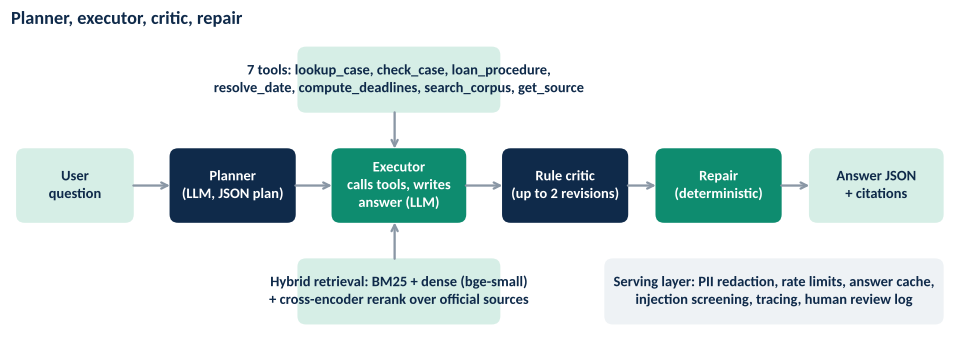

In [2]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 3.6)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 3.6)
def box(x, y, w, h, text, fc, tc="white"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.1", fc=fc, ec="none"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", color=tc, fontsize=9.5, fontweight="bold")
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=nbkit.GREY, lw=1.5))
box(0.1, 1.4, 1.3, 0.8, "User\nquestion", nbkit.MINT, nbkit.NAVY)
box(1.9, 1.4, 1.4, 0.8, "Planner\n(LLM, JSON plan)", nbkit.NAVY)
box(3.8, 1.4, 1.5, 0.8, "Executor\ncalls tools, writes\nanswer (LLM)", nbkit.TEAL)
box(5.8, 1.4, 1.4, 0.8, "Rule critic\n(up to 2 revisions)", nbkit.NAVY)
box(7.6, 1.4, 1.4, 0.8, "Repair\n(deterministic)", nbkit.TEAL)
box(9.4, 1.4, 1.5, 0.8, "Answer JSON\n+ citations", nbkit.MINT, nbkit.NAVY)
for a, b in [(1.4, 1.9), (3.3, 3.8), (5.3, 5.8), (7.2, 7.6), (9.0, 9.4)]:
    arrow(a, 1.8, b, 1.8)
box(3.4, 2.7, 2.3, 0.7, "7 tools: lookup_case, check_case, loan_procedure,\nresolve_date, compute_deadlines, search_corpus, get_source", nbkit.MINT, nbkit.NAVY)
arrow(4.5, 2.7, 4.5, 2.2)
box(3.4, 0.2, 2.3, 0.7, "Hybrid retrieval: BM25 + dense (bge-small)\n+ cross-encoder rerank over official sources", nbkit.MINT, nbkit.NAVY)
arrow(4.5, 0.9, 4.5, 1.4)
box(7.0, 0.2, 3.9, 0.7, "Serving layer: PII redaction, rate limits, answer cache,\ninjection screening, tracing, human review log", "#EEF2F5", nbkit.NAVY)
ax.set_title("Planner, executor, critic, repair", loc="left")
plt.show()

## Headline: how far each stage got us

End-to-end accuracy is deliberately strict. A row only counts if **all six** checks pass: right behaviour, every required
fact present, no forbidden phrase, exact finding codes, valid citations, drafts marked not sent. The whiskers are 95%
Wilson intervals. They matter: with 34 test rows the interval is about 30 points wide.

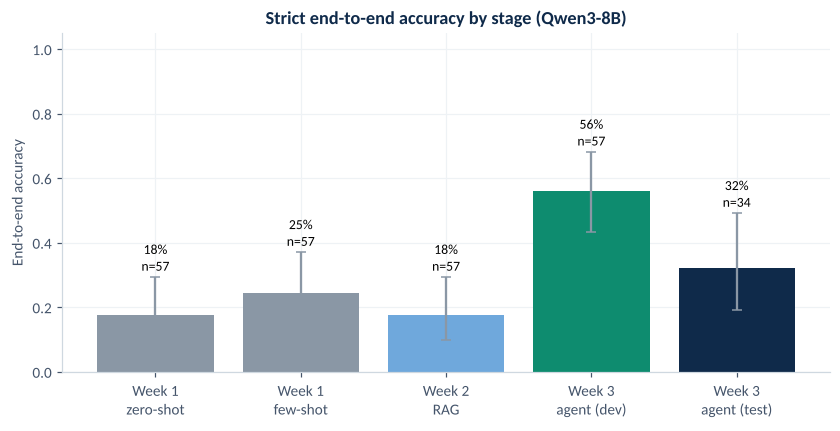

In [3]:
def k_n(path_summary, key="end_to_end_accuracy", n_key="items"):
    s = json.load(open(path_summary)); return round(s[key] * s[n_key]), s[n_key]

base = pd.read_csv(config.RESULTS / "baseline/week1_qwen3_8b/summary.csv").set_index("strategy")
rag = pd.read_csv(config.RESULTS / "rag/week2_qwen3_8b/summary.csv").set_index("strategy")
rows = [
    ("Week 1\nzero-shot", round(base.loc["S0_ZERO_SHOT", "end_to_end_accuracy"] * 57), 57),
    ("Week 1\nfew-shot", round(base.loc["S1_FEW_SHOT", "end_to_end_accuracy"] * 57), 57),
    ("Week 2\nRAG", round(rag.loc["RAG_RETRIEVED", "end_to_end_accuracy"] * 57), 57),
    ("Week 3\nagent (dev)", *k_n(config.RESULTS / "agent/w3_dev_final/summary.json")),
    ("Week 3\nagent (test)", *k_n(config.RESULTS / "agent/w3_test_final/summary.json")),
]
fig, ax = plt.subplots(figsize=(9, 4))
nbkit.ci_bars(ax, [r[0] for r in rows], [r[1] for r in rows], [r[2] for r in rows],
              colors=[nbkit.GREY, nbkit.GREY, nbkit.SKY, nbkit.TEAL, nbkit.NAVY])
ax.set_ylabel("End-to-end accuracy"); ax.set_title("Strict end-to-end accuracy by stage (Qwen3-8B)")
plt.show()

**Read-out for the business.** The agent more than doubled the baseline on the dev split (about 18% to 56%). The test
number (32%) is lower, and two things are true at once: the test split is small (34 rows, so the plausible range is
19% to 49%), and the dev split was used for tuning, so it is a little optimistic. Notebook 01 explains how the
v2 evaluation set addresses both, and notebook 04 shows where the test rows lose their point.

**Plain-language reading of "56%".** More than half of all rows pass every one of six strict checks. Behaviour (picking
the right kind of response) is right in about 74% of rows, finding codes are right in 100%, and the gap is mostly
"a required fact was missing from the wording", not "the answer was wrong".

## How to run this project

* **Offline (no model needed).** Every notebook runs top to bottom from saved results, the deterministic tools, the
  eval set and the corpus index. This is what you use for a demo on a laptop.
* **Live.** Paste your team key into `.env` (`LLM_API_KEY=`) and restart the kernel. `RUN_LIVE = True` is already set in
  the setup cell and switches itself off while the key is missing. Live cells are clearly marked.

In [4]:
missing = config.missing_llm_env()
print("LLM endpoint configured:", not missing, "" if not missing else f"(missing: {', '.join(missing)})")
print("Eval set in use:", config.EVAL_VERSION)
for p in ["src/rto_copilot", "notebooks", "data/eval", "data/cases", "results", "docs", "tests"]:
    print(f"{p:<20}", len(list((ROOT / p).rglob('*'))), "files")

LLM endpoint configured: False (missing: LLM_API_KEY)
Eval set in use: v2
src/rto_copilot      45 files
notebooks            7 files
data/eval            3 files
data/cases           2 files
results              57 files
docs                 5 files
tests                9 files
